## 기초데이터과학 (01분반)

## Lab 06. 데이터 정제 실습

### 진행 방식

- **문제 단위**로 진행하며, 문제마다 제한시간이 있음
- 코드 틀에서 `None` 으로 비어 있는 부분만 채우면 됨
- `print` 문은 이미 작성되어 있으므로 수정 불필요
- 실행 결과가 아래 **기대 출력**과 같으면 정답
- 제한시간이 끝나면 다 같이 풀이 진행. 못 풀었으면 그때 고치면 됨

### 실습 내용

| 문제 | 내용 | 작성할 것 |
|---|---|---|
| 1 | 결측치 확인과 제거 | 코드 |
| 2 | 결측치 대체 방법 비교 | 코드 |
| 3 | 극단치 확인과 결측 처리 | 코드 + 결과 해석 |
| 4 | 결측치와 이상치가 섞인 데이터 정리 | 코드 |

---

## 실습 데이터

- 문제 1~3은 타이타닉 승객 데이터를 사용
- 아래 셀을 먼저 실행할 것

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

titanic = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

print(titanic.shape)
print(titanic.head(3))

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  


---

## 문제 1. 결측치 확인과 제거 (제한시간 10분)

#### 1-1. 열별 결측치 개수를 구하고, 결측치가 **1개 이상인 열만** 출력하시오.
#### 1-2. `Age` 에 결측치가 있는 행을 제거하여 `t_age` 에 저장하시오.
#### 1-3. `Age` 와 `Embarked` 중 하나라도 결측치가 있는 행을 제거하여 `t_two` 에 저장하시오.

> **힌트**
> - 1-1: 결측치 개수를 구한 결과도 Series 이므로 조건으로 걸러낼 수 있음

In [5]:
# 1-1. 결측치가 있는 열만 출력
na_count = titanic.isna().sum()
na_cols  = na_count[na_count > 0]

# 1-2. Age 결측 행 제거
t_age = titanic.dropna(subset=['Age'])

# 1-3. Age, Embarked 결측 행 제거
t_two = titanic.dropna(subset=['Age', 'Embarked'])

print("[1-1]")
print(na_cols)
print()
print("[1-2] 원본:", titanic.shape[0], "행 -> Age 결측 제거:", t_age.shape[0], "행")
print("[1-3] Age, Embarked 결측 제거:", t_two.shape[0], "행")

[1-1]
Age         177
Cabin       687
Embarked      2
dtype: int64

[1-2] 원본: 891 행 -> Age 결측 제거: 714 행
[1-3] Age, Embarked 결측 제거: 712 행


**기대 출력**

```
[1-1]
Age         177
Cabin       687
Embarked      2
dtype: int64

[1-2] 원본: 891 행 -> Age 결측 제거: 714 행
[1-3] Age, Embarked 결측 제거: 712 행
```

### 아래 셀을 실행하기 전에 생각해 볼 것

- 이번에는 `Age`, `Cabin`, `Embarked` **세 열** 중 하나라도 결측치가 있는 행을 제거하려 함
- 1-1의 결과를 참고하여, 891행 중 **몇 행이 남을지** 예측해 볼 것

> 나의 예측: 약 180행, `Cabin`에 결측치가 687개 있어 이 열까지 기준에 넣으면 대부분이 제거될 것 같다


In [6]:
t_three = titanic.dropna(subset = ['Age', 'Cabin', 'Embarked'])

print("세 열 기준 결측 제거:", t_three.shape[0], "행")
print("남은 비율:", round(t_three.shape[0] / titanic.shape[0] * 100, 1), "%")

세 열 기준 결측 제거: 183 행
남은 비율: 20.5 %


---

## 문제 2. 결측치 대체 방법 비교 (제한시간 12분)

- `Age` 의 결측치 177개를 처리하는 네 가지 방법을 비교하려 함

| 변수 | 처리 방법 |
|---|---|
| `age_drop` | 결측치 제거 |
| `age_zero` | 0 으로 대체 |
| `age_mean` | 평균으로 대체 |
| `age_median` | 중앙값으로 대체 |

#### 2-1. 네 가지 방법으로 처리한 `Age` 를 각각 만드시오.
#### 2-2. 출력된 비교표를 보고, **0으로 대체하는 방법의 문제점**을 설명하시오.

> **힌트**
> - 2-1: 원본 `titanic` 은 바꾸지 말고, `titanic['Age']` 에서 시작하여 각 결과를 Series 로 만들 것

In [7]:
age = titanic['Age']

# 2-1. 네 가지 처리 방법
age_drop   = age.dropna()
age_zero   = age.fillna(0)
age_mean   = age.fillna(age.mean())
age_median = age.fillna(age.median())

compare = pd.DataFrame({
    '결측 제거': [age_drop.count(),   age_drop.mean(),   age_drop.median(),   age_drop.std()],
    '0 대체'   : [age_zero.count(),   age_zero.mean(),   age_zero.median(),   age_zero.std()],
    '평균 대체' : [age_mean.count(),   age_mean.mean(),   age_mean.median(),   age_mean.std()],
    '중앙값 대체': [age_median.count(), age_median.mean(), age_median.median(), age_median.std()]
}, index = ['개수', '평균', '중앙값', '표준편차'])

print(compare.round(2))

       결측 제거   0 대체  평균 대체  중앙값 대체
개수    714.00  891.0  891.0  891.00
평균     29.70   23.8   29.7   29.36
중앙값    28.00   24.0   29.7   28.00
표준편차   14.53   17.6   13.0   13.02


**기대 출력**

```
       결측 제거   0 대체  평균 대체  중앙값 대체
개수    714.00  891.0  891.0  891.00
평균     29.70   23.8   29.7   29.36
중앙값    28.00   24.0   29.7   28.00
표준편차   14.53   17.6   13.0   13.02
```

#### 2-2 답안

> 이 셀을 더블클릭하여 아래에 2~3문장으로 작성

- 0으로 대체한 경우의 문제점: 나이가 알려지지 않은 177명을 모두 0세로 간주하게 되어 실제 연령 분포를 왜곡한다. 그 결과 평균이 약 29.70세에서 23.80세로 낮아지고, 0세에 값이 몰려 다른 처리 방법보다 표준편차도 커진다.


---

## 문제 3. 극단치 확인과 결측 처리 (제한시간 15분)

- 타이타닉 승객의 요금(`Fare`)에 극단치가 있는지 확인하려 함

#### 3-1. `Fare` 의 상자 그림을 그리시오.

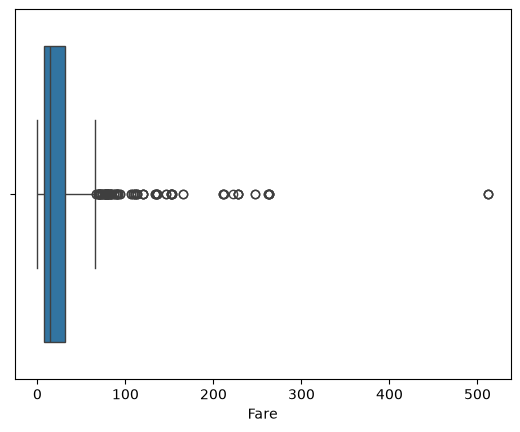

In [8]:
# 3-1. Fare 상자 그림
sns.boxplot(x=titanic['Fare'])
plt.xlabel('Fare')
plt.show()


#### 3-2. `Fare` 의 1사분위수, 3사분위수, IQR 을 구하고, 상자 그림 기준의 하한과 상한을 구하시오.
#### 3-3. 원본을 복사한 `t_fare` 에서, 정상 범위를 벗어난 `Fare` 를 결측 처리하시오.
#### 3-4. 극단치로 판정된 승객이 **객실 등급별로 몇 명**인지 구하시오.

> **힌트**
> - 3-2: 하한과 상한은 숫자로 옮겨 적지 말고 변수로 사용할 것
> - 3-4: 극단치 조건으로 행을 먼저 걸러낸 뒤 등급별 빈도를 구할 것

In [9]:
# 3-2. 사분위수와 경계
q1  = titanic['Fare'].quantile(0.25)
q3  = titanic['Fare'].quantile(0.75)
iqr = q3 - q1

low_limit = q1 - 1.5 * iqr
up_limit  = q3 + 1.5 * iqr

# 3-3. 경계를 벗어난 값 결측 처리
t_fare = titanic.copy()
t_fare['Fare'] = t_fare['Fare'].where(t_fare['Fare'].between(low_limit, up_limit))

# 3-4. 극단치로 판정된 승객의 등급별 인원
outliers = titanic[(titanic['Fare'] < low_limit) | (titanic['Fare'] > up_limit)]
by_class = outliers['Pclass'].value_counts().sort_index()

print("[3-2] Q1:", round(q1, 2), " Q3:", round(q3, 2), " IQR:", round(iqr, 2))
print("[3-2] 하한:", round(low_limit, 2), " 상한:", round(up_limit, 2))
print()
print("[3-3] 결측 처리된 개수:", t_fare['Fare'].isna().sum())
print()
print("[3-4] 극단치 승객의 등급별 인원")
print(by_class)

[3-2] Q1: 7.91  Q3: 31.0  IQR: 23.09
[3-2] 하한: -26.72  상한: 65.63

[3-3] 결측 처리된 개수: 116

[3-4] 극단치 승객의 등급별 인원
Pclass
1    104
2      5
3      7
Name: count, dtype: int64


**기대 출력**

```
[3-2] Q1: 7.91  Q3: 31.0  IQR: 23.09
[3-2] 하한: -26.72  상한: 65.63

[3-3] 결측 처리된 개수: 116

[3-4] 극단치 승객의 등급별 인원
Pclass
1    104
2      5
3      7
Name: count, dtype: int64
```

#### 3-5. 위 결과를 보고 다음 물음에 답하시오.

- 극단치로 판정된 116명의 요금을 **모두 결측 처리하고 제거하는 것이 적절한가?**
- 3-4의 결과를 근거로 2~3문장으로 쓸 것

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 적절한가: 116명의 요금을 모두 결측 처리하고 제거하는 것은 적절하지 않다
- 그렇게 판단한 근거: 극단치 116명 중 104명이 1등석 승객으로 높은 요금이 실제 객실 등급의 특성일 수 있다. 일괄 삭제하면 1등석 승객이 과소 대표되어 분석이 편향될 수 있으므로 요금의 입력 오류 여부와 분석 목적을 먼저 확인해야 한다


---

## 문제 4. 결측치와 이상치가 섞인 데이터 정리 (제한시간 12분)

- 어느 쇼핑몰의 주문 기록이며, 입력 과정의 문제로 결측치와 이상치가 섞여 있음
- 아래 셀을 먼저 실행할 것

In [10]:
data = {
    '주문번호': [101, np.nan, 102, 103, 104, 105, 106, 107, 108, 109, 110, np.nan],
    '상품명'  : ['키보드', np.nan, '마우스', np.nan, '모니터', '마우스',
                '키보드', '마우스', np.nan, '키보드', '모니터', np.nan],
    '수량'    : [1, np.nan, np.nan, 2, 1, 3, -5, np.nan, 1, 1, 1, np.nan],
    '가격'    : [50000, np.nan, 25000, 15000, 200000, 25000,
                50000, 25000, 200000, 50000, np.nan, np.nan],
    '고객등급': ['Gold', np.nan, 'Silver', 'Bronze', 'Gold', np.nan,
                'Silver', 'Silver', 'Gold', 'Bronze', 'Silver', np.nan]
}
orders = pd.DataFrame(data)

print(orders)

     주문번호  상품명   수량        가격    고객등급
0   101.0  키보드  1.0   50000.0    Gold
1     NaN  NaN  NaN       NaN     NaN
2   102.0  마우스  NaN   25000.0  Silver
3   103.0  NaN  2.0   15000.0  Bronze
4   104.0  모니터  1.0  200000.0    Gold
5   105.0  마우스  3.0   25000.0     NaN
6   106.0  키보드 -5.0   50000.0  Silver
7   107.0  마우스  NaN   25000.0  Silver
8   108.0  NaN  1.0  200000.0    Gold
9   109.0  키보드  1.0   50000.0  Bronze
10  110.0  모니터  1.0       NaN  Silver
11    NaN  NaN  NaN       NaN     NaN


#### 4-1. 열별 결측치 개수를 출력하고, **모든 값이 결측치인 행**을 삭제하여 `o1` 에 저장하시오.

> **힌트**
> - `dropna( )` 는 기본적으로 결측치가 **하나라도** 있으면 그 행을 지움. 이 기준을 바꾸는 매개변수가 있음

In [11]:
# 4-1
na_count = orders.isna().sum()
o1 = orders.dropna(subset=['주문번호'])

print(na_count)
print()
print("삭제 전:", orders.shape[0], "행 -> 삭제 후:", o1.shape[0], "행")

주문번호    2
상품명     4
수량      4
가격      3
고객등급    3
dtype: int64

삭제 전: 12 행 -> 삭제 후: 10 행


**기대 출력**

```
주문번호    2
상품명     4
수량      4
가격      3
고객등급    3
dtype: int64

삭제 전: 12 행 -> 삭제 후: 10 행
```

#### 4-2. `o1` 을 복사한 `o2` 에서 아래 순서대로 처리하시오.

1. `수량` 에서 **존재할 수 없는 값**(0 이하)을 결측 처리
2. `수량` 의 결측치를 **평균의 소수점 이하를 버린 정수**로 대체
3. `상품명` 의 결측치를 `'기타'` 로 대체

#### 4-3. `o2` 를 복사한 `o3` 에서 아래 처리를 하시오.

1. `가격` 의 결측치를 **중앙값**으로 대체
2. `고객등급` 의 결측치를 **가장 많이 나타나는 값(최빈값)** 으로 대체

> **힌트**
> - 4-2: 평균은 이상치를 처리한 **뒤에** 구해야 함
> - 4-3: 값별 빈도를 구한 뒤, 가장 큰 값의 **인덱스**를 꺼내면 최빈값이 됨

In [12]:
# 4-2
o2 = o1.copy()
o2['수량'] = o2['수량'].mask(o2['수량'] <= 0)
qty_mean = int(o2['수량'].mean())
o2['수량'] = o2['수량'].fillna(qty_mean)
o2['상품명'] = o2['상품명'].fillna('기타')

# 4-3
o3 = o2.copy()
price_median = o3['가격'].median()
grade_mode   = o3['고객등급'].value_counts().idxmax()
o3['가격']     = o3['가격'].fillna(price_median)
o3['고객등급'] = o3['고객등급'].fillna(grade_mode)

print("[4-2] 수량 평균(정수):", qty_mean)
print("[4-3] 가격 중앙값:", price_median, " / 고객등급 최빈값:", grade_mode)
print()
print(o3)
print()
print("남은 결측치:", o3.isna().sum().sum(), "개")

[4-2] 수량 평균(정수): 1
[4-3] 가격 중앙값: 50000.0  / 고객등급 최빈값: Silver

     주문번호  상품명   수량        가격    고객등급
0   101.0  키보드  1.0   50000.0    Gold
2   102.0  마우스  1.0   25000.0  Silver
3   103.0   기타  2.0   15000.0  Bronze
4   104.0  모니터  1.0  200000.0    Gold
5   105.0  마우스  3.0   25000.0  Silver
6   106.0  키보드  1.0   50000.0  Silver
7   107.0  마우스  1.0   25000.0  Silver
8   108.0   기타  1.0  200000.0    Gold
9   109.0  키보드  1.0   50000.0  Bronze
10  110.0  모니터  1.0   50000.0  Silver

남은 결측치: 0 개


**기대 출력**

```
[4-2] 수량 평균(정수): 1
[4-3] 가격 중앙값: 50000.0  / 고객등급 최빈값: Silver

     주문번호  상품명   수량        가격    고객등급
0   101.0  키보드  1.0   50000.0    Gold
2   102.0  마우스  1.0   25000.0  Silver
3   103.0   기타  2.0   15000.0  Bronze
4   104.0  모니터  1.0  200000.0    Gold
5   105.0  마우스  3.0   25000.0  Silver
6   106.0  키보드  1.0   50000.0  Silver
7   107.0  마우스  1.0   25000.0  Silver
8   108.0   기타  1.0  200000.0    Gold
9   109.0  키보드  1.0   50000.0  Bronze
10  110.0  모니터  1.0   50000.0  Silver

남은 결측치: 0 개
```